# CBB prediction prototype - analysis walkthrough

**SAMPLE - PROTOTYPE** on one past season. This notebook only *reads* the outputs of `python run_all.py`; every number below is printed by code from `output/results.json` and the processed tables.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
R = json.loads((ROOT / "output" / "results.json").read_text())


## 1. Data
The preferred sources (Barttorvik, cbbdata, ESPN) are probed first. The source actually used is shown below. No betting lines were invented.

In [2]:
print(R["data"]["source_used"])
display(pd.DataFrame(R["data"]["source_probe"]).T[["status"]])
print({k: v for k, v in R["data"].items() if k.startswith("games") or k in ("date_min", "date_max", "neutral_site_games", "real_betting_lines_available")})
games = pd.read_parquet(ROOT / "data/processed/games.parquet")
games[["date","home_name","away_name","neutral","home_score","away_score","h1_home","h1_away","poss"]].head()

hoopR-mbb-data (ESPN-derived box scores) from public GitHub, season 2023-24


,status
barttorvik,unreachable
cbbdata_api,unreachable
espn_scoreboard,unreachable


{'games_completed_in_schedule': 6243, 'games_with_box_scores': 6240, 'games_with_first_half_scores': 6240, 'date_min': '2023-11-06', 'date_max': '2024-04-08', 'neutral_site_games': 744, 'real_betting_lines_available': False}


,date,home_name,away_name,neutral,home_score,away_score,h1_home,h1_away,poss
0,2023-11-06,Tulsa,Central Arkansas,False,70,53,33.0,27.0,67.1000
1,2023-11-06,Northwestern,Binghamton,False,72,61,36.0,39.0,68.3375
2,2023-11-06,Syracuse,New Hampshire,False,83,72,44.0,32.0,77.9250
3,2023-11-06,Minnesota,Bethune-Cookman,False,80,60,46.0,22.0,69.6375
4,2023-11-06,Nebraska,Lindenwood,False,84,52,51.0,24.0,71.0250


## 2. Features: as-of-date only
Each game's features use only games **before** its date. The check below is the same one asserted in `tests/test_leakage.py` (which also proves invariance to truncated and corrupted future data).

In [3]:
feats = pd.read_parquet(ROOT / "data/processed/features.parquet")
print("rows:", len(feats), "| every row's latest data date < game date:", bool((feats.hist_max_date < feats.date).all()))
feats[["date","home_name","away_name","d_srs","d_net_eff","d_form10_margin","exp_tempo","b_margin","margin"]].head()

rows: 4196 | every row's latest data date < game date: True


,date,home_name,away_name,d_srs,d_net_eff,d_form10_margin,exp_tempo,b_margin,margin
0,2023-12-10,Eastern Illinois,Central Arkansas,6.120356,24.312768,16.011111,70.034154,22.227242,-3.0
1,2023-12-10,Texas A&M,Memphis,1.723557,6.554045,3.611111,68.755513,9.706267,-6.0
2,2023-12-10,VCU,Alcorn State,2.914468,26.038489,18.444444,68.898330,23.140084,28.0
3,2023-12-10,Saint Joseph's,Princeton,-6.535564,-0.107996,0.777778,66.416895,5.128272,4.0
4,2023-12-10,Charleston,Rhode Island,1.988377,-9.694123,-6.680556,69.104340,-1.499059,15.0


## 3. Walk-forward results (held-out games only)
Models are refit on an expanding window and scored on the next unseen month. Baseline A = always home / home-court margin; Baseline B = efficiency-margin formula.

In [4]:
m = R["metrics"]
print("held-out games:", m["n_test_games"], m["test_start"][:10], "to", m["test_end"][:10])
display(pd.DataFrame(m["ml"]).T.set_index("name").astype(float).round(4))
display(pd.DataFrame(m["mae"]).T.round(2))

held-out games: 3587 2024-01-01 to 2024-04-08


,accuracy,log_loss,brier
name,,,
Baseline A (always home),0.6022,0.6760,0.2413
Baseline B (rating formula),0.6811,0.5941,0.2049
Decision tree (depth 3),0.6627,0.6126,0.2107
LightGBM (uncalibrated),0.6652,0.6086,0.2099
LightGBM (Platt-calibrated),0.6602,0.6085,0.2110


,A,B,GBDT,n
margin,10.71,9.57,9.43,3587.0
total,14.63,13.50,13.49,3587.0
h1_margin,7.84,7.30,7.42,3587.0
h1_total,8.42,7.94,8.03,3587.0


### Is LightGBM really different from the simple formula?
Paired bootstrap over games (difference = LightGBM minus Baseline B). An interval that includes 0 means statistically indistinguishable.

In [5]:
b = pd.DataFrame({k: v for k, v in m["bootstrap"].items() if k.endswith("_minus_B")}).T
b["ci_low"] = b["ci95"].apply(lambda x: x[0]); b["ci_high"] = b["ci95"].apply(lambda x: x[1])
display(b[["mean_diff","ci_low","ci_high","excludes_zero","lower_is_better"]].round(4))
display(pd.DataFrame(m["per_fold"]).round(3))

,mean_diff,ci_low,ci_high,excludes_zero,lower_is_better
log_loss_gbdt_minus_B,0.014403,0.0057,0.0228,True,True
accuracy_gbdt_minus_B,-0.020909,-0.0343,-0.0081,True,False
mae_margin_gbdt_minus_B,-0.144487,-0.2613,-0.0208,True,True
mae_total_gbdt_minus_B,-0.012131,-0.1727,0.1625,False,True
mae_h1_margin_gbdt_minus_B,0.119763,0.0465,0.1951,True,True
mae_h1_total_gbdt_minus_B,0.095628,-0.0035,0.1892,False,True


,fold,n,start,end,acc_gbdt,acc_B,acc_A,ll_gbdt,ll_B,mae_margin_gbdt,mae_margin_B
0,1,1386,2024-01-01,2024-02-01,0.647,0.677,0.600,0.632,0.603,9.650,9.710
1,2,1395,2024-02-01,2024-03-01,0.670,0.700,0.601,0.586,0.579,9.406,9.498
2,3,806,2024-03-01,2024-05-01,0.665,0.655,0.608,0.608,0.604,9.078,9.458


### Calibration, error by target and feature importance

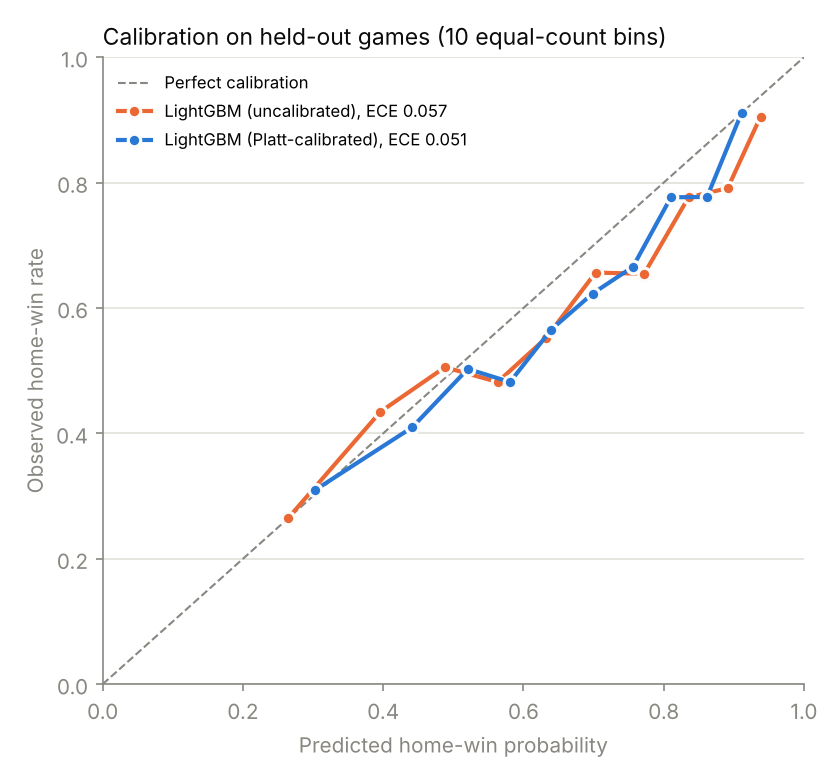

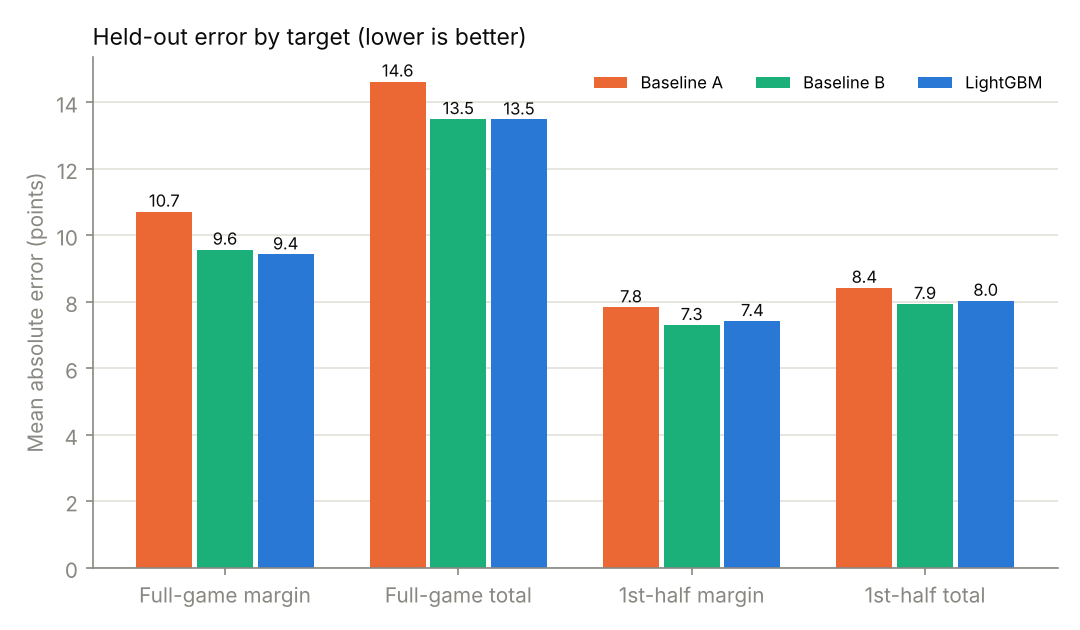

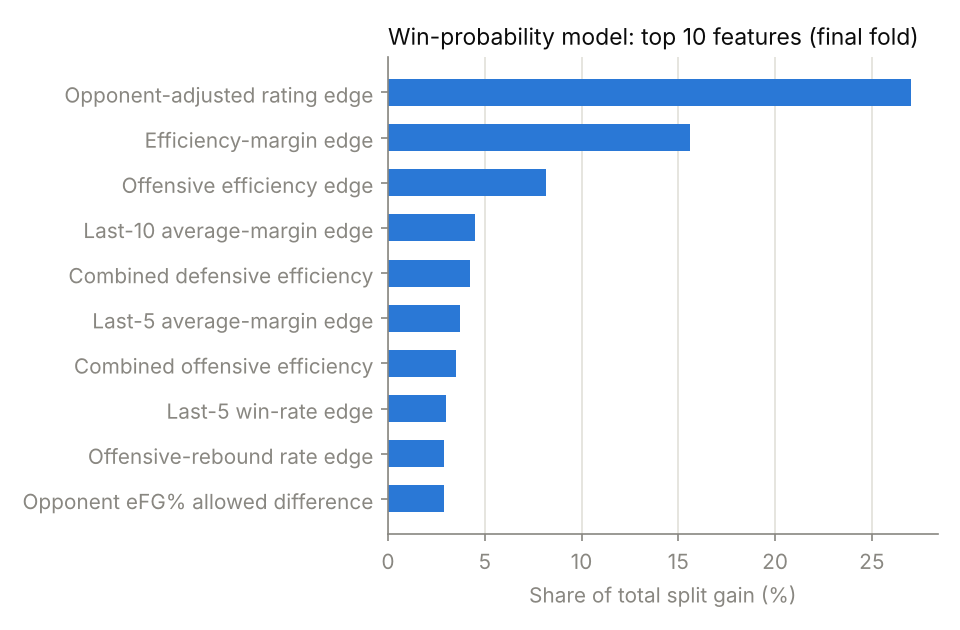

In [6]:
for f in ("calibration.png", "mae_comparison.png", "feature_importance.png"):
    display(Image(filename=str(ROOT / "output" / f), width=560))

### Interpretable decision tree (depth 3)
Plain-English rules from the final fold's tree.

In [7]:
print("\n\n".join(m["tree_rules"]))

IF Opponent-adjusted rating edge (home minus away) is at most -9.58 THEN home team wins 12% of the time (n=125 training games)

IF Opponent-adjusted rating edge (home minus away) is between -9.58 and -5.92 THEN home team wins 30% of the time (n=314 training games)

IF Opponent-adjusted rating edge (home minus away) is between -5.92 and -0.21 AND Efficiency-margin edge (home minus away) is at most -3.26 THEN home team wins 47% of the time (n=800 training games)

IF Opponent-adjusted rating edge (home minus away) is between -5.92 and -0.21 AND Efficiency-margin edge (home minus away) is above -3.26 THEN home team wins 61% of the time (n=320 training games)

IF Opponent-adjusted rating edge (home minus away) is between -0.21 and 3.80 AND Last-10 average-margin edge (home minus away) is at most 5.22 THEN home team wins 65% of the time (n=664 training games)

IF Opponent-adjusted rating edge (home minus away) is between -0.21 and 3.80 AND Last-10 average-margin edge (home minus away) is abo

## 4. ROI backtest
Without real closing lines no ROI can be validated. The only simulation is against a *proxy* line (Baseline B's own number) and is **not market performance**.

B - ROI could not be validated because free historical betting lines were not available; with the client's API access to closing lines, this is the first thing I would test.
PROXY - NOT REAL MARKET RESULTS

PROXY - spread


,n_bets,win_rate,units,roi_pct,max_drawdown_units
0.5,3098.0,0.572,286.818,9.258,26.273
1.0,2731.0,0.580,291.091,10.659,18.091
2.0,1954.0,0.595,264.364,13.529,24.818
3.0,1405.0,0.614,242.545,17.263,13.818
4.0,946.0,0.618,170.818,18.057,9.000



PROXY - total


,n_bets,win_rate,units,roi_pct,max_drawdown_units
0.5,3284.0,0.560,224.909,6.849,19.636
1.0,3032.0,0.567,249.727,8.236,16.545
2.0,2565.0,0.575,252.818,9.856,16.000
3.0,2096.0,0.585,246.455,11.758,14.727
4.0,1689.0,0.593,222.000,13.144,11.909


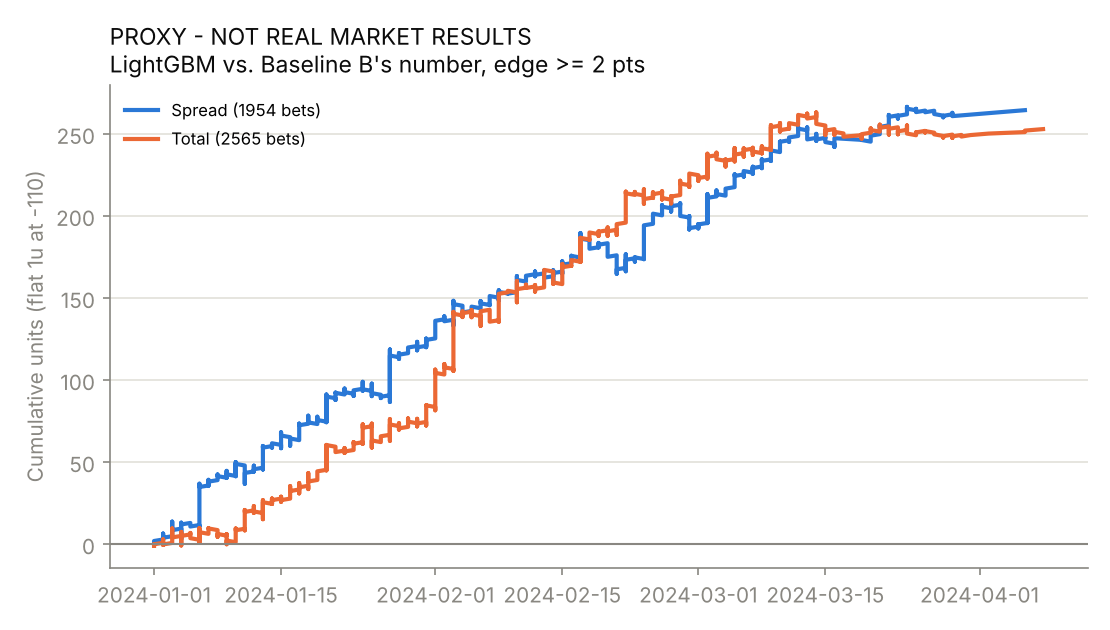

In [8]:
bt = R["backtest"]
print(bt["case"], "-", bt.get("message", ""))
print(bt.get("label", ""))
if bt["case"] == "B":
    for mk in ("spread", "total"):
        print("\nPROXY -", mk)
        display(pd.DataFrame(bt[mk]).T[["n_bets","win_rate","units","roi_pct","max_drawdown_units"]].astype(float).round(3))
    display(Image(filename=str(ROOT / "output" / "proxy_cumulative_profit.png"), width=560))

## 5. Game card
One real held-out game, generated from pre-game information only.

Auburn at Tennessee 2024-02-28 | selection rule: highest combined pre-game opponent-adjusted rating among held-out, regular-season, non-neutral games


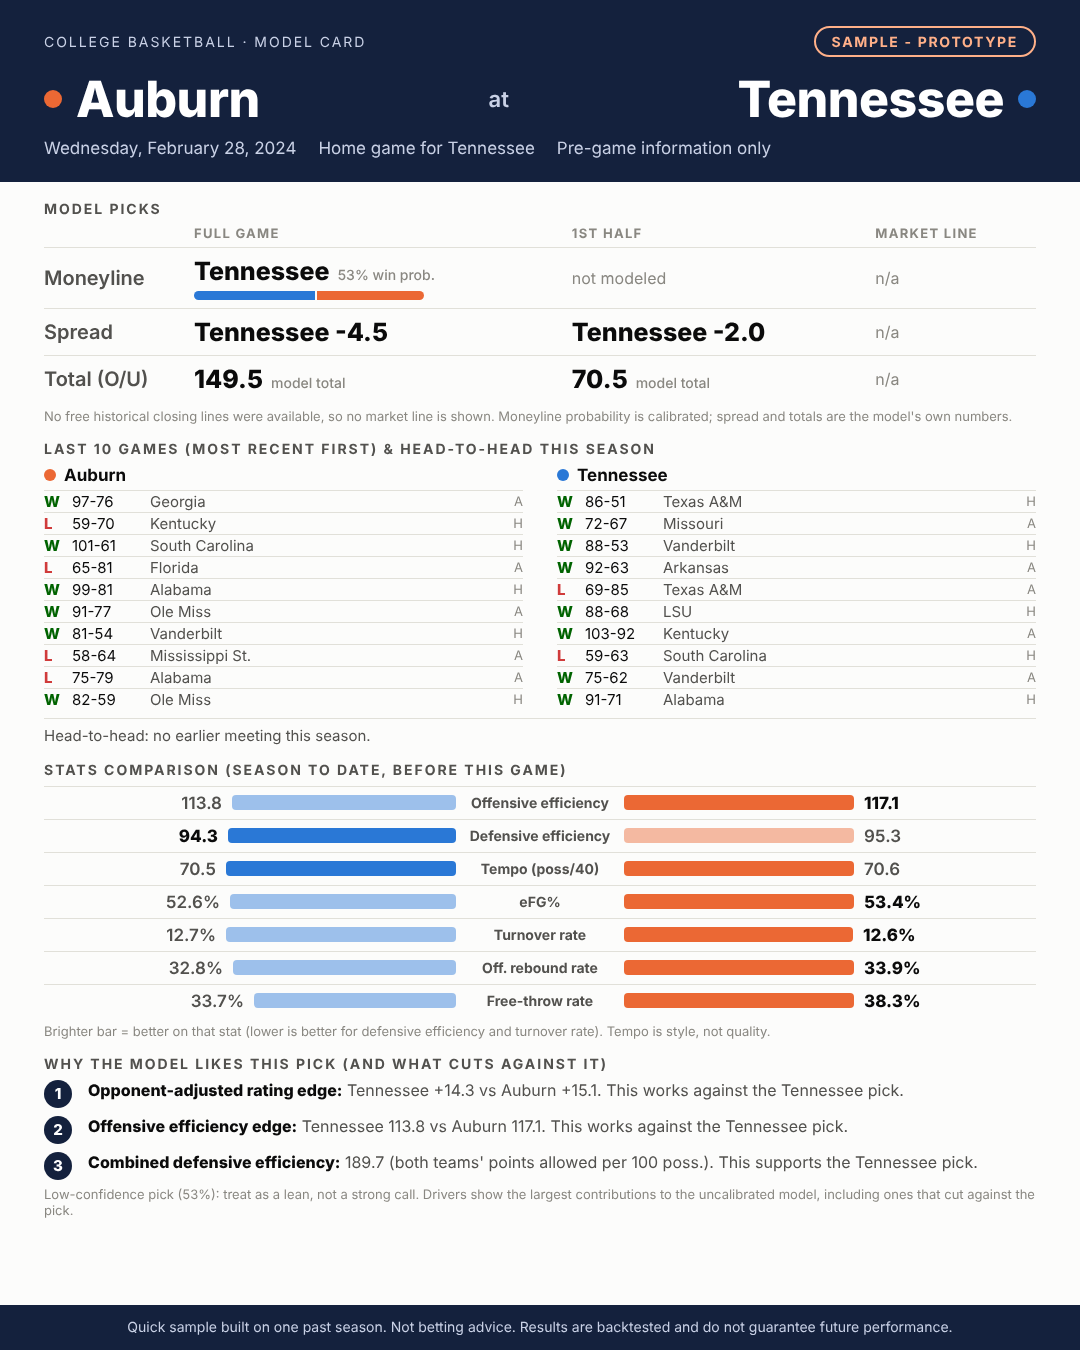

In [9]:
print(R["card"]["game"], R["card"]["date"][:10], "| selection rule:", R["card"]["selection_rule"])
display(Image(filename=str(ROOT / "output" / "game_card.png"), width=520))

## 6. Limitations
One season; no injuries/lineups/line movement/real market lines; fixed untuned hyper-parameters; ESPN-derived box scores rather than Barttorvik; bootstrap treats games as independent. See the README for the full list and the extension plan.